In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

In [2]:
batch1 = pickle.load(open(r'batch1.pkl', 'rb'))
#remove batteries that do not reach 80% capacity
del batch1['b1c8']
del batch1['b1c10']
del batch1['b1c12']
del batch1['b1c13']
del batch1['b1c22']

In [3]:
numBat1 = len(batch1.keys())
numBat1

41

In [4]:
batch2 = pickle.load(open(r'batch2.pkl','rb'))

In [6]:
# There are four cells from batch1 that carried into batch2, we'll remove the data from batch2
# and put it with the correct cell from batch1
batch2_keys = ['b2c7', 'b2c8', 'b2c9', 'b2c15', 'b2c16']
batch1_keys = ['b1c0', 'b1c1', 'b1c2', 'b1c3', 'b1c4']
add_len = [662, 981, 1060, 208, 482];

In [7]:
for i, bk in enumerate(batch1_keys):
    batch1[bk]['cycle_life'] = batch1[bk]['cycle_life'] + add_len[i]
    for j in batch1[bk]['summary'].keys():
        if j == 'cycle':
            batch1[bk]['summary'][j] = np.hstack((batch1[bk]['summary'][j], batch2[batch2_keys[i]]['summary'][j] + len(batch1[bk]['summary'][j])))
        else:
            batch1[bk]['summary'][j] = np.hstack((batch1[bk]['summary'][j], batch2[batch2_keys[i]]['summary'][j]))
    last_cycle = len(batch1[bk]['cycles'].keys())
    for j, jk in enumerate(batch2[batch2_keys[i]]['cycles'].keys()):
        batch1[bk]['cycles'][str(last_cycle + j)] = batch2[batch2_keys[i]]['cycles'][jk]

In [8]:
del batch2['b2c7']
del batch2['b2c8']
del batch2['b2c9']
del batch2['b2c15']
del batch2['b2c16']

In [9]:
numBat2 = len(batch2.keys())
numBat2

43

In [11]:
batch3 = pickle.load(open(r'batch3.pkl','rb'))
# remove noisy channels from batch3
del batch3['b3c37']
del batch3['b3c2']
del batch3['b3c23']
del batch3['b3c32']
del batch3['b3c42']
del batch3['b3c43']

In [12]:
numBat3 = len(batch3.keys())
numBat3

40

In [14]:
numBat = numBat1 + numBat2 + numBat3
numBat

124

In [15]:
bat_dict = {**batch1, **batch2, **batch3}

Text(0, 0.5, 'Discharge Capacity (Ah)')

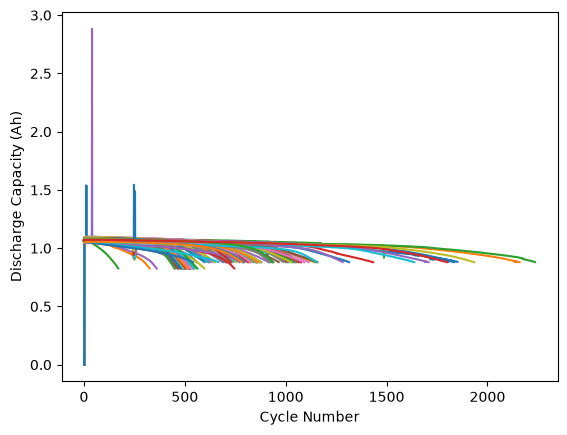

In [16]:
for i in bat_dict.keys():
    plt.plot(bat_dict[i]['summary']['cycle'], bat_dict[i]['summary']['QD'])
plt.xlabel('Cycle Number')
plt.ylabel('Discharge Capacity (Ah)')

In [17]:
import pandas as pd

df= pd.DataFrame(bat_dict)

In [18]:
df.head()

,b1c0,b1c1,b1c2,b1c3,b1c4,b1c5,b1c6,b1c7,b1c9,b1c11,...,b3c33,b3c34,b3c35,b3c36,b3c38,b3c39,b3c40,b3c41,b3c44,b3c45
cycle_life,[[1852.0]],[[2160.0]],[[2237.0]],[[1434.0]],[[1709.0]],[[1074.0]],[[636.0]],[[870.0]],[[1054.0]],[[788.0]],...,[[1284.0]],[[1158.0]],[[1093.0]],[[923.0]],[[1935.0]],[[1156.0]],[[796.0]],[[786.0]],[[940.0]],[[1801.0]]
charge_policy,3.6C(80%)-3.6C,3.6C(80%)-3.6C,3.6C(80%)-3.6C,4C(80%)-4C,4C(80%)-4C,4.4C(80%)-4.4C,4.8C(80%)-4.8C,4.8C(80%)-4.8C,5.4C(40%)-3.6C,5.4C(50%)-3C,...,5C(67%)-4C-newstructure,5.3C(54%)-4C-newstructure,5.6C(19%)-4.6C-newstructure,5.6C(36%)-4.3C-newstructure,5C(67%)-4C-newstructure,5.3C(54%)-4C-newstructure,5.6C(19%)-4.6C-newstructure,5.6C(36%)-4.3C-newstructure,5.3C(54%)-4C-newstructure,4.8C(80%)-4.8C-newstructure
summary,"{'IR': [0.0, 0.016742354, 0.016724309, 0.01668...","{'IR': [0.0, 0.017038831, 0.017009802, 0.01692...","{'IR': [0.0, 0.01686798, 0.016831938, 0.016718...","{'IR': [0.0, 0.016369704, 0.016315572, 0.01632...","{'IR': [0.0, 0.016787428, 0.016740341, 0.01673...","{'IR': [0.0, 0.016437579, 0.016396422, 0.01636...","{'IR': [0.0, 0.017001977, 0.016977131, 0.01693...","{'IR': [0.0, 0.016311171, 0.016267659, 0.01623...","{'IR': [0.0, 0.016978227, 0.01692898, 0.016933...","{'IR': [0.0, 0.016575078, 0.016582273, 0.01658...",...,"{'IR': [0.015608473, 0.015511206, 0.015512635,...","{'IR': [0.01546871, 0.015438841, 0.015394062, ...","{'IR': [0.015503207, 0.01549053, 0.015479395, ...","{'IR': [0.015283138, 0.015267849, 0.015275053,...","{'IR': [0.016009804, 0.015988033, 0.015961975,...","{'IR': [0.015740374, 0.015740704, 0.015716039,...","{'IR': [0.015553804, 0.015561919, 0.015549388,...","{'IR': [0.018552294, 0.01854171, 0.018510165, ...","{'IR': [0.015744392, 0.015722955, 0.015682839,...","{'IR': [0.015778109, 0.015742011, 0.015711647,..."
cycles,"{'0': {'I': [0, 0], 'Qc': [0, 0], 'Qd': [0, 0]...","{'0': {'I': [0, 0], 'Qc': [0, 0], 'Qd': [0, 0]...","{'0': {'I': [0, 0], 'Qc': [0, 0], 'Qd': [0, 0]...","{'0': {'I': [0, 0], 'Qc': [0, 0], 'Qd': [0, 0]...","{'0': {'I': [0, 0], 'Qc': [0, 0], 'Qd': [0, 0]...","{'0': {'I': [0, 0], 'Qc': [0, 0], 'Qd': [0, 0]...","{'0': {'I': [0, 0], 'Qc': [0, 0], 'Qd': [0, 0]...","{'0': {'I': [0, 0], 'Qc': [0, 0], 'Qd': [0, 0]...","{'0': {'I': [0, 0], 'Qc': [0, 0], 'Qd': [0, 0]...","{'0': {'I': [0, 0], 'Qc': [0, 0], 'Qd': [0, 0]...",...,"{'0': {'I': [0.4446896636363636, 0.74768759999...","{'0': {'I': [0.36538210909090907, 0.6768590727...","{'0': {'I': [0.28115359090909087, 0.6164724181...","{'0': {'I': [0.33352591818181815, 0.7284268454...","{'0': {'I': [0.2911827818181818, 0.54510636363...","{'0': {'I': [0.42202342727272724, 0.5800594, 0...","{'0': {'I': [0.2727786, 0.6122276999999999, 0....","{'0': {'I': [0.3870253090909091, 0.72554848181...","{'0': {'I': [0.4198421090909091, 0.68663163636...","{'0': {'I': [0.5633510272727271, 0.82326021818..."


### Train and Test Split
If you are interested in using the same train/test split as the paper, use the indices specified below

In [14]:
test_ind = np.hstack((np.arange(0,(numBat1+numBat2),2),83))
train_ind = np.arange(1,(numBat1+numBat2-1),2)
secondary_test_ind = np.arange(numBat-numBat3,numBat);

# **Making a CSV/Pandas Dataframe of all the data out of our Binary PKL Extracted Files**

In [ ]:
import pandas as pd
import numpy as np
import pickle
from scipy.stats import skew, kurtosis

def extract_all_possible_features(pkl_file_path, bad_cells_list, batch_num):
    with open(pkl_file_path, 'rb') as f:
        batch_data = pickle.load(f)

    # Clean bad/incomplete channels
    for cell in bad_cells_list:
        if cell in batch_data:
            del batch_data[cell]

    features = []
    
    for cell_id, cell_data in batch_data.items():
        summary = cell_data['summary']
        cycles = cell_data['cycles']
        
        cycle_life = float(cell_data['cycle_life'][0][0])
        policy = str(cell_data['charge_policy'])
        
        
        # 1. Delta Q Features: Cycle 100 minus Cycle 10 (Index '99' & '9')
        try:
            qdlin_10 = cycles['9']['Qdlin']
            qdlin_100 = cycles['99']['Qdlin']
            delta_Q = qdlin_100 - qdlin_10
            
            var_dQ = np.var(delta_Q)
            log_var_delta_Q = np.log10(var_dQ) if var_dQ > 0 else np.nan
            min_dQ = np.min(delta_Q)
            log_min_delta_Q = np.log10(np.abs(min_dQ)) if min_dQ != 0 else np.nan
            
            mean_delta_Q = np.mean(delta_Q)
            max_delta_Q = np.max(delta_Q)
            skew_delta_Q = skew(delta_Q)
            kurt_delta_Q = kurtosis(delta_Q)
            std_delta_Q = np.std(delta_Q)
        except KeyError:
            # Fallback if battery failed prior to cycle 100
            log_var_delta_Q = log_min_delta_Q = mean_delta_Q = np.nan
            max_delta_Q = skew_delta_Q = kurt_delta_Q = std_delta_Q = np.nan

        # 2. Discharge Capacity (Qd) Features (Cycles 2 to 100)
        qd = summary['QD'][1:100]
        valid_qd_idx = np.where(qd > 0)[0]
        if len(valid_qd_idx) > 1:
            qd_slope, qd_intercept = np.polyfit(valid_qd_idx, qd[valid_qd_idx], 1)
            qd_max = np.max(qd[valid_qd_idx])
            qd_2 = qd[valid_qd_idx[0]]
            qd_100 = qd[valid_qd_idx[-1]]
            qd_diff_100_2 = qd_100 - qd_2
        else:
            qd_slope = qd_intercept = qd_max = qd_2 = qd_100 = qd_diff_100_2 = np.nan

        # 3. Internal Resistance (IR) Features (Cycles 2 to 100)
        ir = summary['IR'][1:100]
        valid_ir_idx = np.where(ir > 0)[0]
        if len(valid_ir_idx) > 1:
            ir_slope, ir_intercept = np.polyfit(valid_ir_idx, ir[valid_ir_idx], 1)
            ir_min = np.min(ir[valid_ir_idx])
            ir_max = np.max(ir[valid_ir_idx])
            ir_mean = np.mean(ir[valid_ir_idx])
            ir_2 = ir[valid_ir_idx[0]]
            ir_100 = ir[valid_ir_idx[-1]]
            ir_diff_100_2 = ir_100 - ir_2
        else:
            ir_slope = ir_intercept = ir_min = ir_max = np.nan
            ir_mean = ir_2 = ir_100 = ir_diff_100_2 = np.nan

        # 4. Thermal Features (Cycles 2 to 100)
        t_avg = summary['Tavg'][1:100]
        t_max = summary['Tmax'][1:100]
        t_min = summary['Tmin'][1:100]
        
        avg_temp = np.mean(t_avg) if len(t_avg) > 0 else np.nan
        max_temp = np.max(t_max) if len(t_max) > 0 else np.nan
        min_temp = np.min(t_min) if len(t_min) > 0 else np.nan
        temp_integral = np.trapezoid(t_avg) if len(t_avg) > 0 else np.nan

        # 5. Charge Time Features (Cycles 2 to 100)
        ct = summary['chargetime'][1:100]
        valid_ct_idx = np.where(ct > 0)[0]
        if len(valid_ct_idx) > 1:
            ct_slope = np.polyfit(valid_ct_idx, ct[valid_ct_idx], 1)[0]
            ct_avg = np.mean(ct[valid_ct_idx])
        else:
            ct_slope = ct_avg = np.nan

        # Append row dictionary
        features.append({
            # Identifiers & Metadata
            'cell_id': cell_id,
            'batch': batch_num,
            'charge_policy': policy,
            
            # Target Variables
            'cycle_life': cycle_life,
            'log_cycle_life': np.log10(cycle_life),
            
            # Delta Q Curve Features
            'log_var_delta_Q': log_var_delta_Q,
            'min_delta_Q': log_min_delta_Q,
            'mean_delta_Q': mean_delta_Q,
            'max_delta_Q': max_delta_Q,
            'skew_delta_Q': skew_delta_Q,
            'kurt_delta_Q': kurt_delta_Q,
            'std_delta_Q': std_delta_Q,
            
            # Capacity Features
            'qd_slope': qd_slope,
            'qd_intercept': qd_intercept,
            'qd_max': qd_max,
            'qd_diff_100_2': qd_diff_100_2,
            
            # IR Features
            'ir_slope': ir_slope,
            'ir_intercept': ir_intercept,
            'ir_min': ir_min,
            'ir_max': ir_max,
            'ir_mean': ir_mean,
            'ir_diff_100_2': ir_diff_100_2,
            
            # Thermal Features
            'avg_temp': avg_temp,
            'max_temp': max_temp,
            'min_temp': min_temp,
            'temp_integral': temp_integral,
            
            # Charge Time Features
            'ct_slope': ct_slope,
            'ct_avg': ct_avg
        })
        
    return pd.DataFrame(features)

# Define exclusions for each batch
b1_bad = ['b1c8', 'b1c10', 'b1c12', 'b1c13', 'b1c22']
b2_bad = ['b2c7', 'b2c8', 'b2c9', 'b2c15', 'b2c16']
b3_bad = ['b3c37', 'b3c2', 'b3c23', 'b3c32', 'b3c42']

# Extract features across all 3 batches
df_b1 = extract_all_possible_features('batch1.pkl', b1_bad, 1)
df_b2 = extract_all_possible_features('batch2.pkl', b2_bad, 2)
df_b3 = extract_all_possible_features('batch3.pkl', b3_bad, 3)

# Combine into raw master dataset
df_raw_master = pd.concat([df_b1, df_b2, df_b3], ignore_index=True)
df_raw_master.to_csv('raw_master_battery_features.csv', index=False)

print(f"Raw Master Dataset Created: {df_raw_master.shape[0]} rows x {df_raw_master.shape[1]} columns")

Raw Master Dataset Created: 125 rows x 28 columns


In [3]:
df_raw_master.head()

,cell_id,batch,charge_policy,cycle_life,log_cycle_life,log_var_delta_Q,min_delta_Q,mean_delta_Q,max_delta_Q,skew_delta_Q,...,ir_min,ir_max,ir_mean,ir_diff_100_2,avg_temp,max_temp,min_temp,temp_integral,ct_slope,ct_avg
0,b1c0,1,3.6C(80%)-3.6C,1190.0,3.075547,-5.014861,-2.072648,-0.002873,0.000768,-0.532058,...,0.016444,0.018950,0.016643,-0.000075,31.603747,35.994705,29.012251,3097.042122,-0.000080,13.384231
1,b1c1,1,3.6C(80%)-3.6C,1179.0,3.071514,-5.013960,-1.958457,-0.004100,-0.000088,-0.429375,...,0.016764,0.017039,0.016922,-0.000042,31.330314,34.712265,29.230637,3070.271766,-0.000460,13.374696
2,b1c2,1,3.6C(80%)-3.6C,1177.0,3.070776,-4.737000,-1.764058,-0.004487,0.000013,-1.080194,...,0.016613,0.016878,0.016769,-0.000014,31.479584,35.127342,29.269444,3084.890135,-0.000051,13.378886
3,b1c3,1,4C(80%)-4C,1226.0,3.088490,-4.442613,-1.722149,-0.007456,0.000182,-0.439050,...,0.016098,0.016408,0.016311,0.000039,29.942199,31.691414,29.023619,2934.239337,-0.000125,12.053277
4,b1c4,1,4C(80%)-4C,1227.0,3.088845,-4.647744,-1.855177,-0.005750,0.000046,-0.362548,...,0.016369,0.016787,0.016669,-0.000053,31.448884,35.651741,29.092649,3081.926451,0.000109,12.053314


In [4]:
df_raw_master.columns

Index(['cell_id', 'batch', 'charge_policy', 'cycle_life', 'log_cycle_life',
       'log_var_delta_Q', 'min_delta_Q', 'mean_delta_Q', 'max_delta_Q',
       'skew_delta_Q', 'kurt_delta_Q', 'std_delta_Q', 'qd_slope',
       'qd_intercept', 'qd_max', 'qd_diff_100_2', 'ir_slope', 'ir_intercept',
       'ir_min', 'ir_max', 'ir_mean', 'ir_diff_100_2', 'avg_temp', 'max_temp',
       'min_temp', 'temp_integral', 'ct_slope', 'ct_avg'],
      dtype='str')

**This 28-column feature matrix has extracted all actionable physical, statistical, and thermodynamic signals contained inside those .pkl binary files.**
**A CSV format will help in better data readability and understanding in order to carry the preprocessing and data cleaning steps ahead.**

### **Here, our Data Extraction Process is finally completed and we are left with a raw CSV file consisting all the candidate features that maybe useful and required while training the ML Model.**